# PEnKF

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from rainfall import *
from enkf import *

In [3]:
data = load_data("./data/rainfall.pt")
theta = data["theta"]
x = data["x"]
stations = data["stations"]
y = data["y"]
z = data["z"]
meta = data["meta"]

In [4]:
torch.manual_seed(548)
particles, log_weights, esses, ensembles = penkf(stations, z, n=100, m=10, T=10)

In [5]:
theta[10]

tensor(2.4623)

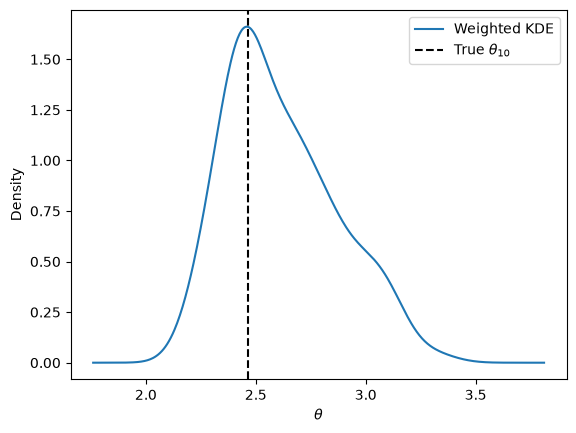

In [6]:
import numpy as np
from plots import *

t = 10
thetas = torch.stack([torch.as_tensor(p) for p in particles]).numpy()
weights = log_weights.exp().numpy()
plot_theta(thetas, theta[t].item(), t, weights,
    save="figures/penkf_filtering_theta.png")

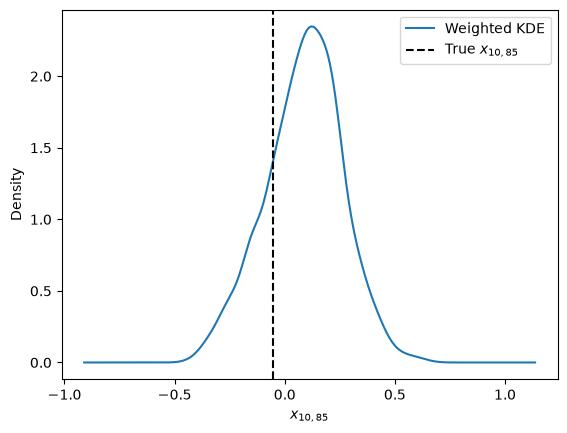

In [7]:
# Posterior samples of x are all ensemble members, each carrying its
# particle's weight divided by the ensemble size
X = torch.stack([torch.stack(e) for e in ensembles]).numpy() # (n, m, grid)
x_weights = np.repeat(weights/X.shape[1], X.shape[1])

rng = np.random.default_rng(0)
k = rng.integers(X.shape[2])
plot_state_marginal(X, x[t].numpy(), t, k, x_weights,
    save="figures/penkf_filtering_marginal.png")

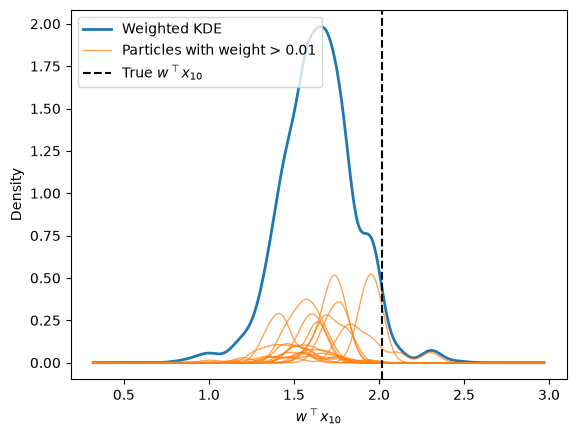

In [8]:
w = rng.standard_normal(X.shape[2])
w /= np.linalg.norm(w)
plot_projection(X, x[t].numpy(), t, w, x_weights, ensembles, weights,
    save="figures/penkf_filtering_projection.png")

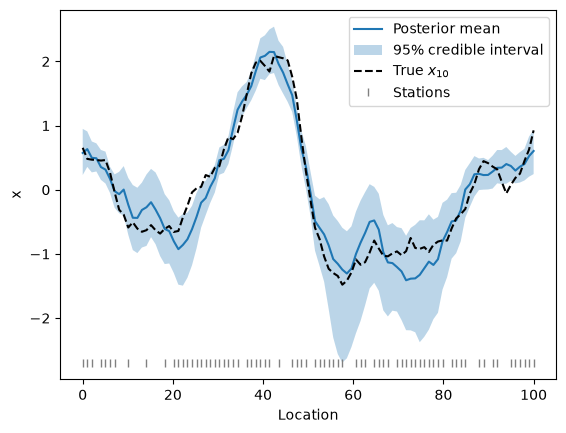

In [9]:
plot_state_band(X, x[t].numpy(), t, stations, x_weights,
    save="figures/penkf_filtering_band.png")

In [ ]:
from metrics import record_metrics
record_metrics("results/penkf.csv", "filtering_T10", X, x[t].numpy(), x_weights)

We have relatively low uncertainty in regions where there is a lot of rainfall.
This makes sense; the only uncertainty comes from y. We have higher uncertainty
at the dry stations because we have to infer based on past behaviour and nearby
stations.

In [10]:
from metrics import record_esses
record_esses("results/penkf_esses.csv", "filtering_T10", esses)
esses

[tensor(1.8613),
 tensor(7.1633),
 tensor(13.5801),
 tensor(2.8151),
 tensor(2.0507),
 tensor(13.3006),
 tensor(22.9516),
 tensor(7.9385),
 tensor(3.2843),
 tensor(15.2655)]

## Single update at $T=10$

In [11]:
torch.manual_seed(548)
particles, log_weights, esses, ensembles = penkf(stations, z[9:10], n=100, m=10, T=1)

In [12]:
record_esses("results/penkf_esses.csv", "single_update_T10", esses)
esses

[tensor(1.4699)]

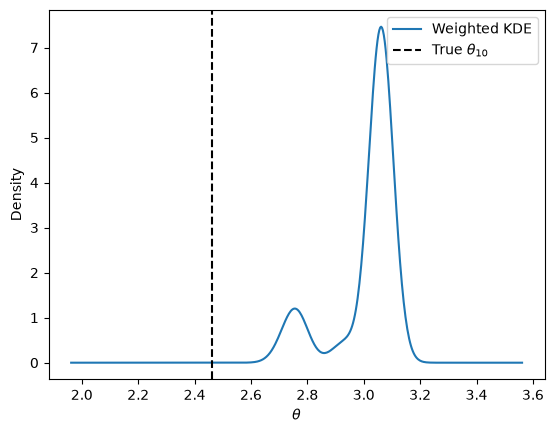

In [13]:
t = 10
thetas = torch.stack([torch.as_tensor(p) for p in particles]).numpy()
weights = log_weights.exp().numpy()
plot_theta(thetas, theta[t].item(), t, weights,
    save="figures/penkf_single_update_theta.png")

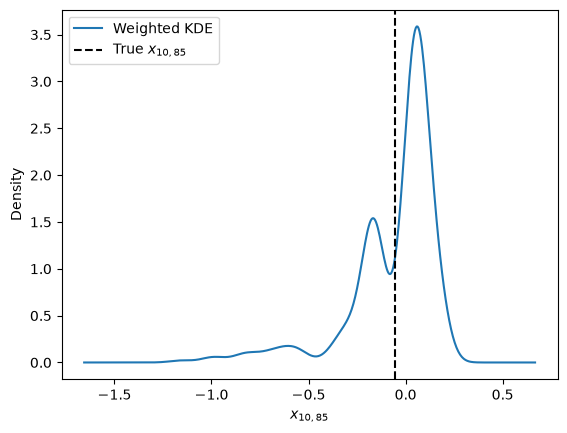

In [14]:
X = torch.stack([torch.stack(e) for e in ensembles]).numpy() # (n, m, grid)
x_weights = np.repeat(weights/X.shape[1], X.shape[1])

rng = np.random.default_rng(0)
k = rng.integers(X.shape[2])
plot_state_marginal(X, x[t].numpy(), t, k, x_weights,
    save="figures/penkf_single_update_marginal.png")

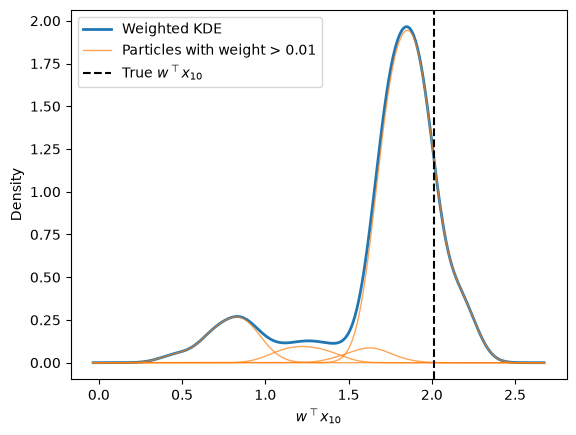

In [15]:
w = rng.standard_normal(X.shape[2])
w /= np.linalg.norm(w)
plot_projection(X, x[t].numpy(), t, w, x_weights, ensembles, weights,
    save="figures/penkf_single_update_projection.png")

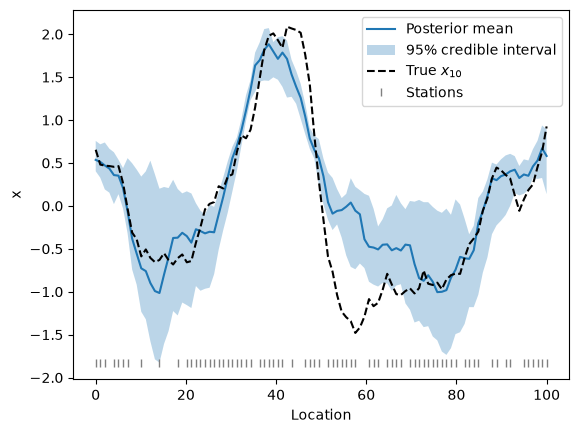

In [16]:
plot_state_band(X, x[t].numpy(), t, stations, x_weights,
    save="figures/penkf_single_update_band.png")

In [ ]:
record_metrics("results/penkf.csv", "single_update_T10", X, x[t].numpy(), x_weights)

## PEnKF no resampling
We run PEnKF with no resampling just to look at ESS values.

In [17]:
torch.manual_seed(548)
particles, log_weights, esses, ensembles = penkf(stations, z, n=100, m=10, T=10, resample=False)
record_esses("results/penkf_esses.csv", "filtering_T10_no_resampling", esses)
esses

[tensor(1.8613),
 tensor(3.2674),
 tensor(3.0917),
 tensor(1.0006),
 tensor(1.0006),
 tensor(1.0000),
 tensor(1.0000),
 tensor(1.7821),
 tensor(1.0007),
 tensor(1.3477)]